In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
from domino.data.data import preprocess_data, process_bed_file_df
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *

import scipy.stats as stats
import pandas as pd
import os
import numpy as np

import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import coolbox
from coolbox.api import *

from tqdm import tqdm

In [2]:
import numpy as np
from scipy.ndimage import binary_dilation
from scipy.stats import pearsonr, spearmanr

def masked_correlation_1d(a, b, w=2):
    if len(a) != len(b):
        raise ValueError("Arrays must have same length")

    # Non-finite in either array
    bad = ~(np.isfinite(a) & np.isfinite(b))

    # Expand by w positions on each side
    structure = np.ones(2*w + 1, dtype=bool)
    bad_expanded = binary_dilation(bad, structure=structure)

    keep = ~bad_expanded

    x = a[keep]
    y = b[keep]

    if len(x) < 10 or len(y) < 10:
        return None, None, keep

    return (
        pearsonr(x, y).statistic,
        spearmanr(x, y).statistic,
        keep,
    )

In [3]:
def get_demeaned_ins_track(row, ins, ins_score_context_bin_width=15000//200):
    chrom, start, end = row.chrom, row.start, row.end
    # get insulation around boundary of interest
    tmp = ins.query('chrom == @chrom and start == @start and end==@end')
    i = tmp.index.item()
    idxs_pos = np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1)
    if (idxs_pos < 0).any():
        return None
    y_pos = np.array([np.array(ins['demeaned_ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    return y_pos

import pysam
from domino.utils.tools import seq_from_df
def get_predicted_track(boundary, ins_score_context_bin_width=10, resolution=200, bp_radius=15_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = f"{ins_dir}/new_larval_CNS_merged.resolution=200bp.insulation_1kb.bed"
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    if tmp.index.item() - bin_radius < 0 or tmp.index.item() + bin_radius + 1 > len(ins_score1):
        return None, None
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    genome_path = '/scratch/gpfs/PRITYKIN/brendan/deeplearning-microc/data/dm6.fa'
    genome_fasta = pysam.FastaFile(genome_path)

    locus_df['direction'] = ["+"] * len(locus_df)
    locus_df.reset_index(inplace=True, drop=True)
    seqs = seq_from_df(genome_fasta, locus_df, DNA_context_length=16*200)
    predictions = model(seqs.to('cuda'))
    predictions = predictions.cpu().detach().flatten()
    
    x, y = np.arange(len(predictions)), predictions
    return x, y

In [ ]:
from tqdm import tqdm

def make_predictions(regions_bound_df):
    predicted_tracks = []
    for i, row in tqdm(regions_bound_df.iterrows(), total=len(regions_bound_df), desc="Processing rows"):
        boundary = (row.chrom, row.start, row.end)
        _, preds = get_predicted_track(boundary)
        predicted_tracks.append(preds.numpy())
    predicted_tracks = np.array(predicted_tracks)
    return predicted_tracks

# saving to larval brain test boundaries
# test_predicted_tracks = make_predictions(lb_test_boundaries)
# np.save('final_supp_sliding_window_lb_test_boundaries_predictions.npy', test_predicted_tracks)

## Larval brain

In [4]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/02_27_2026_final_larval_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

# get true demeaned ins score
lb_ins_ws=1
mean_scaling_window=10
lb_ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
lb_ins1_path = f"{lb_ins_dir}/new_larval_CNS_merged.resolution=200bp.insulation_1kb.bed"
lb_ins_score1 = process_bed_file_df(lb_ins1_path, target_col='ins_score')
lb_ins_score1["demeaned_ins_score"] = lb_ins_score1["ins_score"] - lb_ins_score1["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()


strong_bound_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/02_27_2026_final_larval_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_boundaries_df.bound_score_gt_1.2.nan_offset=20000.stripe_offset=800.csv', index_col=0)
strong_bound_df = strong_bound_df.query('has_stripe_at_bound == False')
strong_bound_df = strong_bound_df.drop_duplicates(['chrom', 'start', 'end'])

examples_to_test = TEST_df.merge(strong_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])
examples_to_train = TRAIN_df.merge(strong_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])

lb_train_boundaries = examples_to_train.reset_index(drop=True)
lb_test_boundaries = examples_to_test.reset_index(drop=True)

# load metadata and predictions
# lb_train_boundaries = pd.read_csv('final_supp_sliding_window_lb_train_boundaries.csv', index_col=0)
# lb_test_boundaries = pd.read_csv('final_supp_sliding_window_lb_test_boundaries.csv', index_col=0)

train_predicted_arr = np.load('final_supp_sliding_window_lb_train_boundaries_predictions.npy')
test_predicted_arr = np.load('final_supp_sliding_window_lb_test_boundaries_predictions.npy')

test_pred_pearson_correlations = []
test_pred_spearman_correlations = []

# get true track regions
# get predictions around each track
for i, row in tqdm(lb_test_boundaries.iterrows(), total=len(lb_test_boundaries), desc="Processing rows"):
    # row = examples_to_test.iloc[100]
    y1 = get_demeaned_ins_track(row, lb_ins_score1)
            
    pred = test_predicted_arr[i]

    pcc, scc, _ = masked_correlation_1d(y1, pred)

    test_pred_pearson_correlations.append(pcc)
    test_pred_spearman_correlations.append(scc)

Processing rows: 100%|██████████| 657/657 [00:08<00:00, 76.11it/s]


In [11]:
train_pred_pearson_correlations = []
train_pred_spearman_correlations = []

for i, row in tqdm(lb_train_boundaries.iterrows(), total=len(lb_train_boundaries), desc="Processing rows"):
    y1 = get_demeaned_ins_track(row, lb_ins_score1)
    
    if y1 is None:
        train_pred_pearson_correlations.append(None)
        train_pred_spearman_correlations.append(None)
        continue
        
    pred = train_predicted_arr[i]

    pcc, scc, _ = masked_correlation_1d(y1, pred)

    train_pred_pearson_correlations.append(pcc)
    train_pred_spearman_correlations.append(scc)

Processing rows: 100%|██████████| 5659/5659 [01:16<00:00, 74.27it/s]


In [12]:
lb_test_boundaries['pred_pearson'] = test_pred_pearson_correlations
lb_test_boundaries['pred_spearman'] = test_pred_spearman_correlations

lb_train_boundaries['pred_pearson'] = train_pred_pearson_correlations
lb_train_boundaries['pred_spearman'] = train_pred_spearman_correlations

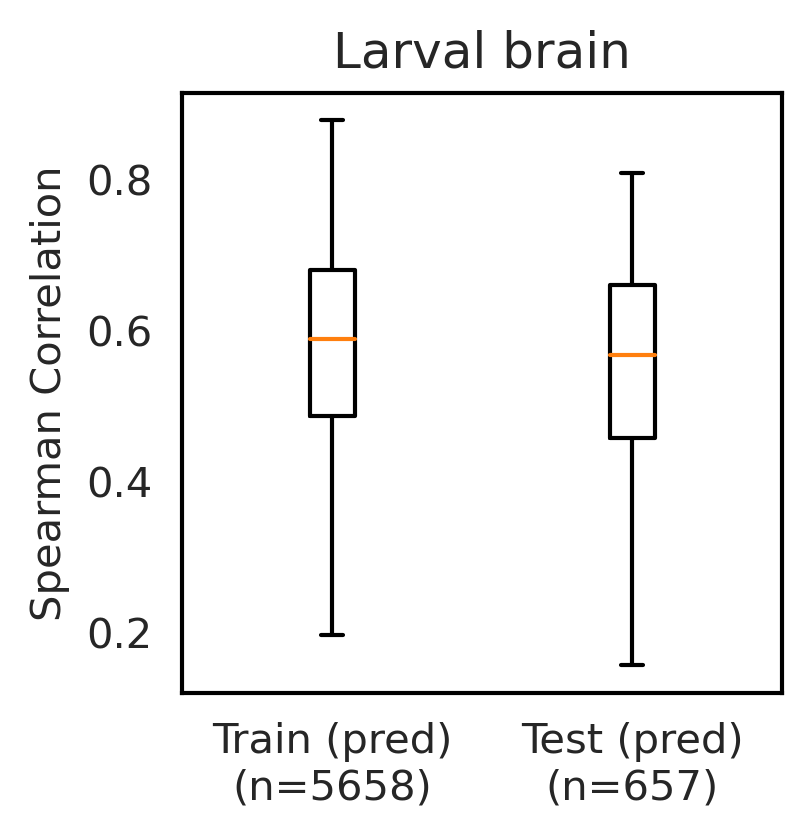

In [14]:
import matplotlib.pyplot as plt

plot_train = lb_train_boundaries.query('~pred_spearman.isnull()')
plot_test = lb_test_boundaries.query('~pred_spearman.isnull()')

train_pred = plot_train.pred_spearman.tolist()
test_pred = plot_test.pred_spearman.tolist()

fig, ax = init_subplots_exact(1,1,x_ratios=[0.5], y_ratios=[0.5], dpi=300)

ax.boxplot(
    [train_pred, test_pred],
    labels = [f"Train (pred)\n(n={len(train_pred)})", f"Test (pred)\n(n={len(test_pred)})"],
    showfliers=False
)

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1)

ax.set_ylabel("Spearman Correlation")
ax.set_title("Larval brain")
ax.grid(False)
plt.show()

## Adult brain

In [15]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13_2025_adult_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

ab_ins_ws=1
mean_scaling_window=10
ab_ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
ab_ins1_path = f"{ab_ins_dir}/adult_CNS_merged.resolution=200bp.insulation_1kb.bed"
ab_ins_score1 = process_bed_file_df(ab_ins1_path, target_col='ins_score')
ab_ins_score1["demeaned_ins_score"] = ab_ins_score1["ins_score"] - ab_ins_score1["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()


strong_bound_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13_2025_adult_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_boundaries_df.bound_score_gt_1.4.nan_offset=20000.stripe_offset=800.csv', index_col=0)
strong_bound_df = strong_bound_df.query('has_stripe_at_bound == False')
strong_bound_df = strong_bound_df.drop_duplicates(['chrom', 'start', 'end'])

examples_to_test = TEST_df.merge(strong_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])
examples_to_train = TRAIN_df.merge(strong_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])

ab_train_boundaries = examples_to_train.reset_index(drop=True)
ab_test_boundaries = examples_to_test.reset_index(drop=True)

# ab_train_boundaries = pd.read_csv('final_supp_sliding_window_ab_train_boundaries.csv', index_col=0)
# ab_test_boundaries = pd.read_csv('final_supp_sliding_window_ab_test_boundaries.csv', index_col=0)

train_predicted_arr = np.load('final_supp_sliding_window_ab_train_boundaries_predictions.npy')
test_predicted_arr = np.load('final_supp_sliding_window_ab_test_boundaries_predictions.npy')

test_pred_pearson_correlations = []
test_pred_spearman_correlations = []

for i, row in tqdm(ab_test_boundaries.iterrows(), total=len(ab_test_boundaries), desc="Processing rows"):
    y1 = get_demeaned_ins_track(row, ab_ins_score1)
            
    pred = test_predicted_arr[i]

    pcc, scc, _ = masked_correlation_1d(y1, pred)

    test_pred_pearson_correlations.append(pcc)
    test_pred_spearman_correlations.append(scc)

ab_test_boundaries['pred_pearson'] = test_pred_pearson_correlations
ab_test_boundaries['pred_spearman'] = test_pred_spearman_correlations

Processing rows: 100%|██████████| 742/742 [00:10<00:00, 72.99it/s]


In [16]:
train_pred_pearson_correlations = []
train_pred_spearman_correlations = []

for i, row in tqdm(ab_train_boundaries.iterrows(), total=len(ab_train_boundaries), desc="Processing rows"):
    y1 = get_demeaned_ins_track(row, ab_ins_score1)
    
    if y1 is None:
        train_pred_pearson_correlations.append(None)
        train_pred_spearman_correlations.append(None)
        continue
        
    pred = train_predicted_arr[i]

    pcc, scc, _ = masked_correlation_1d(y1, pred)

    train_pred_pearson_correlations.append(pcc)
    train_pred_spearman_correlations.append(scc)

ab_train_boundaries['pred_pearson'] = train_pred_pearson_correlations
ab_train_boundaries['pred_spearman'] = train_pred_spearman_correlations

Processing rows: 100%|██████████| 6135/6135 [01:23<00:00, 73.75it/s]


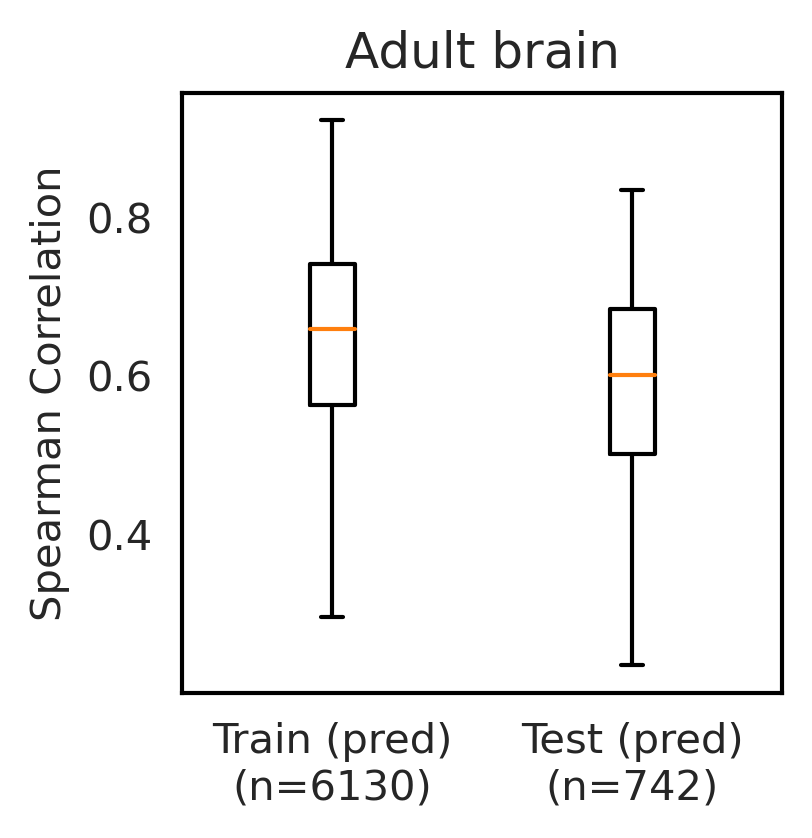

In [34]:
import matplotlib.pyplot as plt

plot_train = ab_train_boundaries.query('~pred_spearman.isnull()')
plot_test = ab_test_boundaries.query('~pred_spearman.isnull()')

train_pred = plot_train.pred_spearman.tolist()
test_pred = plot_test.pred_spearman.tolist()

fig, ax = init_subplots_exact(1,1,x_ratios=[0.5], y_ratios=[0.5], dpi=300)

ax.boxplot(
    [train_pred, test_pred],
    labels = [f"Train (pred)\n(n={len(train_pred)})", f"Test (pred)\n(n={len(test_pred)})"],
    showfliers=False
)

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1)

ax.set_ylabel("Spearman Correlation")
ax.set_title("Adult brain")
ax.grid(False)
plt.show()

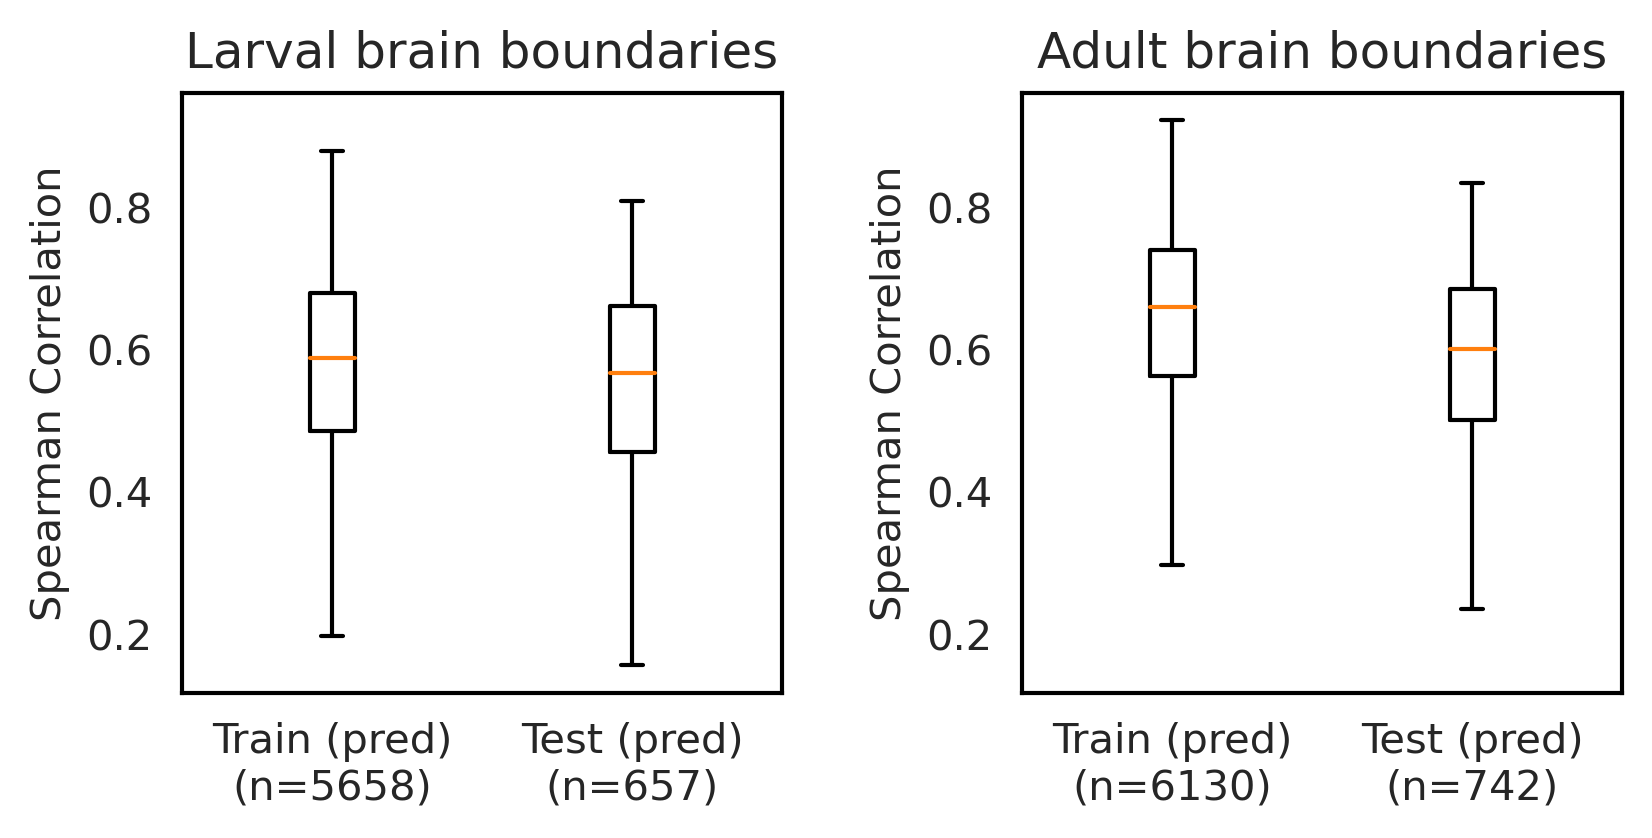

In [24]:
import matplotlib.pyplot as plt


fig, axs = init_subplots_exact(2,1,x_ratios=[0.5] * 2, y_ratios=[0.5], sharey=True, dpi=300, xspace=1.4)

plot_train = lb_train_boundaries.query('~pred_spearman.isnull()')
plot_test = lb_test_boundaries.query('~pred_spearman.isnull()')

train_pred = plot_train.pred_spearman.tolist()
test_pred = plot_test.pred_spearman.tolist()

axs[0].boxplot(
    [train_pred, test_pred],
    labels = [f"Train (pred)\n(n={len(train_pred)})", f"Test (pred)\n(n={len(test_pred)})"],
    showfliers=False
)

plot_train = ab_train_boundaries.query('~pred_spearman.isnull()')
plot_test = ab_test_boundaries.query('~pred_spearman.isnull()')

train_pred = plot_train.pred_spearman.tolist()
test_pred = plot_test.pred_spearman.tolist()

axs[1].boxplot(
    [train_pred, test_pred],
    labels = [f"Train (pred)\n(n={len(train_pred)})", f"Test (pred)\n(n={len(test_pred)})"],
    showfliers=False
)

for ax in axs:
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1)

    ax.set_ylabel("Spearman Correlation")
    ax.grid(False)
    
axs[0].set_title("Larval brain boundaries")
axs[1].set_title("Adult brain boundaries")
plt.show()